# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [54]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

In [55]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [56]:
X_train, y_train = data["train_images"], data["train_labels"].ravel()
X_val,   y_val   = data["val_images"],   data["val_labels"].ravel()
X_test,  y_test  = data["test_images"],  data["test_labels"].ravel()

CLASS_NAMES = ["bazofil", "eozynofil", "erytroblast", "niedojrzałe granulocyty",
               "limfocyt", "monocyt", "neutrofil", "płytka krwi"]
NUM_CLASSES = len(CLASS_NAMES)

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s}: obrazy {X.shape}, typ {X.dtype}, zakres {X.min()}–{X.max()}, etykiety {np.unique(y)}")

train: obrazy (11959, 28, 28, 3), typ uint8, zakres 0–255, etykiety [0 1 2 3 4 5 6 7]
val  : obrazy (1712, 28, 28, 3), typ uint8, zakres 0–255, etykiety [0 1 2 3 4 5 6 7]
test : obrazy (3421, 28, 28, 3), typ uint8, zakres 0–255, etykiety [0 1 2 3 4 5 6 7]


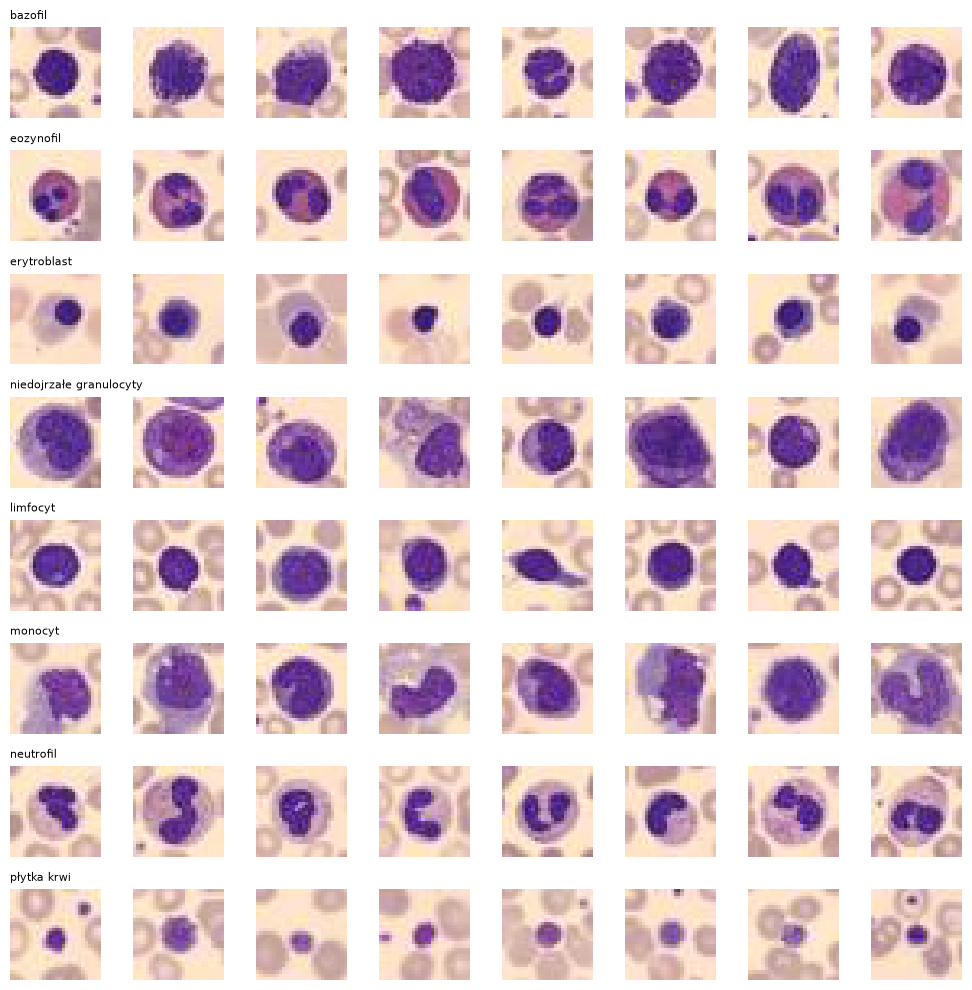

In [57]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(10, 10))
for c in range(NUM_CLASSES):
    idx = np.where(y_train == c)[0][:8]
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train[i])
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

                         train  val  test
bazofil                    852  122   244
eozynofil                 2181  312   624
erytroblast               1085  155   311
niedojrzałe granulocyty   2026  290   579
limfocyt                   849  122   243
monocyt                    993  143   284
neutrofil                 2330  333   666
płytka krwi               1643  235   470


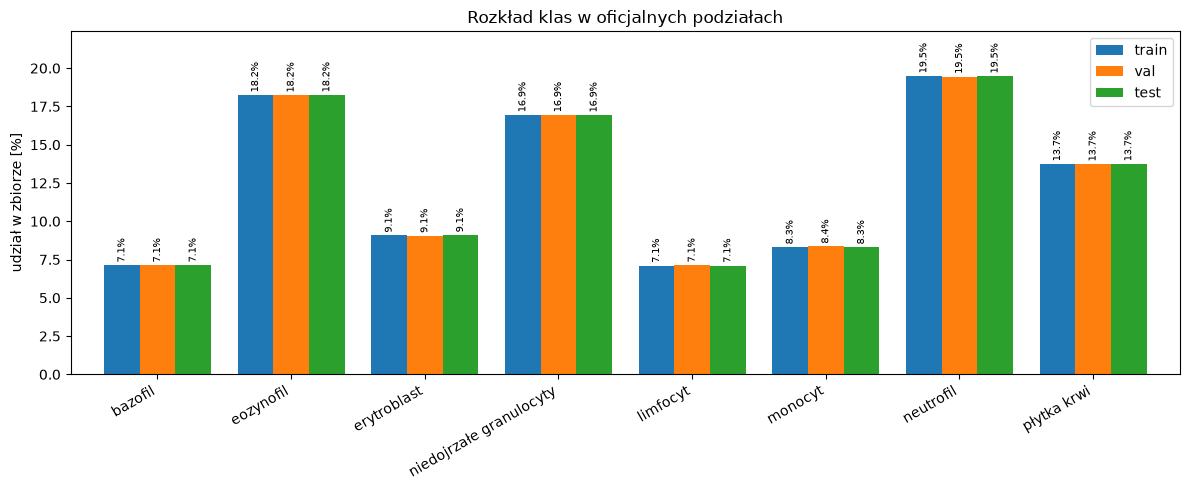

In [58]:
counts = pd.DataFrame({
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val":   np.bincount(y_val,   minlength=NUM_CLASSES),
    "test":  np.bincount(y_test,  minlength=NUM_CLASSES),
}, index=CLASS_NAMES)
print(counts)

percent = counts / counts.sum() * 100

ax = percent.plot.bar(figsize=(12, 5), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=7, rotation=90, padding=2)

ax.set_ylabel("udział w zbiorze [%]")
ax.set_title("Rozkład klas w oficjalnych podziałach")
ax.set_ylim(0, percent.values.max() * 1.15)  
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [59]:
def flat(X):
    return X.reshape(len(X), -1)   # każdy obraz jako jeden wiersz liczb

def n_common(A, B):
    """Ile różnych obrazów występuje jednocześnie w A i w B."""
    a = np.unique(flat(A), axis=0)
    b = np.unique(flat(B), axis=0)
    return len(a) + len(b) - len(np.unique(np.vstack([a, b]), axis=0))

print("Duplikaty w train:", len(X_train) - len(np.unique(flat(X_train), axis=0)))
print("Wspólne train-val:", n_common(X_train, X_val))
print("Wspólne train-test:", n_common(X_train, X_test))
print("Obrazy jednokolorowe:", (flat(X_train).std(axis=1) < 1).sum())

Duplikaty w train: 8
Wspólne train-val: 3
Wspólne train-test: 5
Obrazy jednokolorowe: 0


In [60]:
# Usuwanie duplikatów - tylko ze zbioru treningowego
# 1) duplikaty wewnątrz train
_, first_idx = np.unique(flat(X_train), axis=0, return_index=True)
keep = np.zeros(len(X_train), dtype=bool)
keep[first_idx] = True

# 2) obrazy z train, które występują też w val lub test
eval_imgs = {img.tobytes() for img in np.vstack([X_val, X_test])}
in_eval = np.array([img.tobytes() in eval_imgs for img in X_train])
keep &= ~in_eval

print(f"Usunięto z train: {(~keep).sum()} "
      f"(duplikaty wewnętrzne: {len(X_train) - len(first_idx)}, obecne w val/test: {in_eval.sum()})")

X_train, y_train = X_train[keep], y_train[keep]
print("Nowy rozmiar train:", X_train.shape)

Usunięto z train: 16 (duplikaty wewnętrzne: 8, obecne w val/test: 8)
Nowy rozmiar train: (11943, 28, 28, 3)


                         train  val  test
bazofil                    846  122   244
eozynofil                 2175  312   624
erytroblast               1085  155   311
niedojrzałe granulocyty   2023  290   579
limfocyt                   849  122   243
monocyt                    992  143   284
neutrofil                 2330  333   666
płytka krwi               1643  235   470


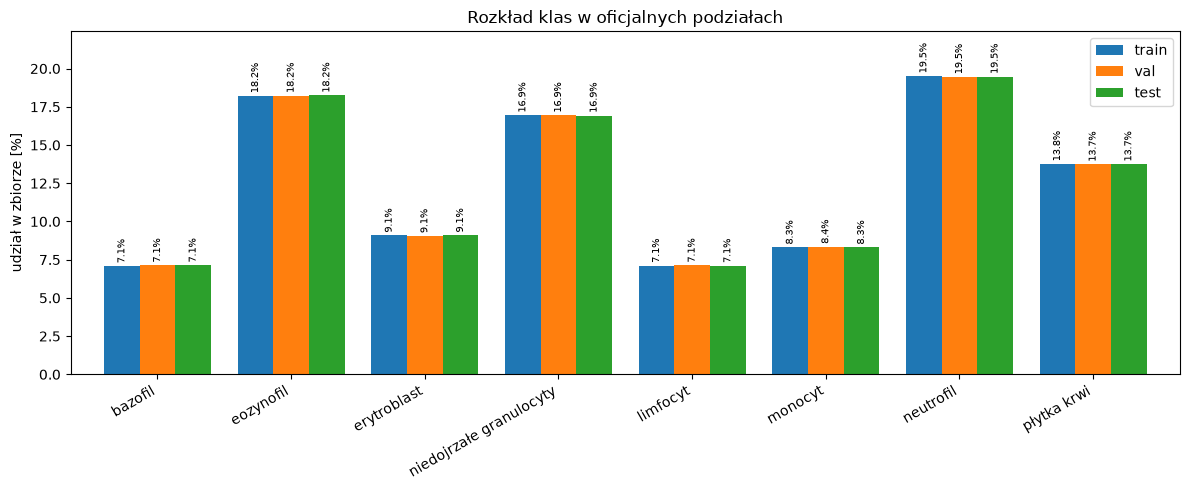

In [61]:
# Sprawdzenie udziałó w podziałach po usunięciu duplikatów
counts = pd.DataFrame({
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "val":   np.bincount(y_val,   minlength=NUM_CLASSES),
    "test":  np.bincount(y_test,  minlength=NUM_CLASSES),
}, index=CLASS_NAMES)
print(counts)

percent = counts / counts.sum() * 100

ax = percent.plot.bar(figsize=(12, 5), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=7, rotation=90, padding=2)

ax.set_ylabel("udział w zbiorze [%]")
ax.set_title("Rozkład klas w oficjalnych podziałach")
ax.set_ylim(0, percent.values.max() * 1.15)  
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Średnia RGB (train): [0.7944 0.6597 0.6962]
Odchylenie RGB (train): [0.2156 0.2416 0.1179]


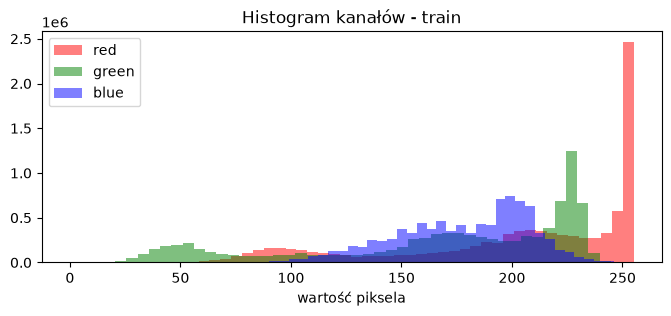

In [62]:
train_mean = (X_train / 255.0).mean(axis=(0, 1, 2))
train_std  = (X_train / 255.0).std(axis=(0, 1, 2))
print("Średnia RGB (train):", train_mean.round(4))
print("Odchylenie RGB (train):", train_std.round(4))

fig, ax = plt.subplots(figsize=(8, 3))
for ch, color in enumerate(["red", "green", "blue"]):
    ax.hist(X_train[..., ch].ravel(), bins=50, alpha=0.5, color=color, label=color)
ax.set_xlabel("wartość piksela")
ax.legend()
ax.set_title("Histogram kanałów - train")
plt.show()

In [63]:
normalize = transforms.Normalize(mean=train_mean.tolist(), std=train_std.tolist())

train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=90),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    normalize,
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    normalize,
])

class BloodDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

train_ds = BloodDataset(X_train, y_train, train_transform)
val_ds   = BloodDataset(X_val,   y_val,   eval_transform)
test_ds  = BloodDataset(X_test,  y_test,  eval_transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

class_counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_weights = torch.tensor(len(y_train) / (NUM_CLASSES * class_counts), dtype=torch.float32)
print("Wagi klas:", class_weights.numpy().round(2))

Wagi klas: [1.76 0.69 1.38 0.74 1.76 1.5  0.64 0.91]


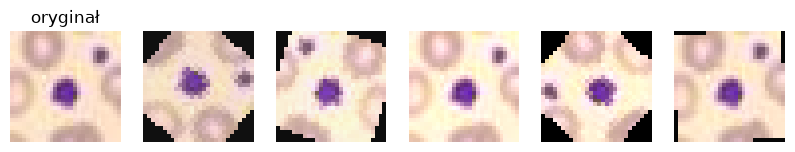

In [64]:
# Augmentacja
img = X_train[0]
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
axes[0].imshow(img)
axes[0].set_title("oryginał")
for ax in axes[1:]:
    t = train_transform(img).numpy().transpose(1, 2, 0) * train_std + train_mean
    ax.imshow(np.clip(t, 0, 1))
for ax in axes:
    ax.axis("off")
plt.show()

### **Wnioski z eksploracji i uzasadnienie preprocessingu**

- Dane to kolorowe (RGB) obrazy mikroskopowe komórek krwi 28x28, 8 klas, wartości pikseli 0-255.
- Zachowanie oficjalnego podziału train/val/test.
- Rozkład klas jest niezbilanoswany (najmniej bazofili i limfocytów, najwięcej - neurofili), jednak proporcje zostały zachowane we wszystkich podziałach proporcje. Dlatego też będę stosować F1 macro i wagi klas w funkcji straty, liczone tylko z train.
- Brak pustych obrazów. Kilka duplikatów (8 w train, 3 wspólne z val, 5 z test). Duplikaty z train datasetu zostały usunięte aby zapobiec wyciekowi danych. Mogło to wpłynąć na różnice w udziale klas w poszczególnych datasetach, ale z tego co widać różnica jest nieznancza.
- Średnia i odchylenie kanałów RGB liczone sa tylko na train i stosowane do val i test, żeby uniknąć wyciekowi danych (w normalizacji).
- Augmentacja (tylko trein) - odbicia i obroty, bo komórka nie ma ustalonej orientacji. Lekka zmana jasności i kontrastu, bo barwienie i oświetlenie preparató się różnią. Bez mocnych zmian koloru i przycieniania, bo przy 28x28 łatwo zniszczyć szczegóły, a kolor jest ważną cechą komórek.
- Na val i test datasetach jedynie zrobiono konwersje do tensora i normalizacje, bez losowości.

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [65]:
import copy
import time

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Urządzenie:", device)

Urządzenie: cpu


In [66]:
class BloodCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()

        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            block(3, 32),     # 28x28 -> 14x14
            block(32, 64),    # 14x14 -> 7x7
            block(64, 128),   # 7x7   -> 3x3
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),   # 128 x 3x3 -> 128 x 1x1
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BloodCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Liczba parametrów: {n_params:,}")
print("Kształt wyjścia:", model(torch.randn(2, 3, 28, 28).to(device)).shape)  # oczekiwane (2, 8)

Liczba parametrów: 288,936
Kształt wyjścia: torch.Size([2, 8])


In [67]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        n += len(y)
    return total_loss / n  # średni błąd

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * len(y)
        all_preds.append(out.argmax(dim=1).cpu())
        all_labels.append(y.cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    acc = (preds == labels).mean()
    f1 = f1_score(labels, preds, average="macro")
    return total_loss / len(labels), acc, f1, preds

In [68]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

MAX_EPOCHS = 50
PATIENCE = 8          # ile epok bez poprawy val F1, zanim przerwiemy

best_f1, best_epoch, epochs_no_improve = 0.0, 0, 0
best_state = None
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion)
    scheduler.step(val_f1)

    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                    "val_acc": val_acc, "val_f1": val_f1, "lr": optimizer.param_groups[0]["lr"]})
    print(f"Epoka {epoch:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val acc {val_acc:.4f} | val F1 {val_f1:.4f} | {time.perf_counter() - t0:.1f}s")

    if val_f1 > best_f1:
        best_f1, best_epoch, epochs_no_improve = val_f1, epoch, 0
        best_state = copy.deepcopy(model.state_dict())   # zapamiętaj najlepsze wagi
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping po epoce {epoch}")
            break

model.load_state_dict(best_state)
print(f"Najlepszy model: epoka {best_epoch}, val F1 = {best_f1:.4f}")

Epoka  1 | train loss 0.7648 | val loss 0.5265 | val acc 0.8370 | val F1 0.8022 | 31.8s
Epoka  2 | train loss 0.4579 | val loss 0.6790 | val acc 0.8002 | val F1 0.7137 | 28.6s
Epoka  3 | train loss 0.3796 | val loss 0.2577 | val acc 0.9100 | val F1 0.9036 | 32.2s
Epoka  4 | train loss 0.3171 | val loss 0.3680 | val acc 0.8657 | val F1 0.8466 | 36.9s
Epoka  5 | train loss 0.3044 | val loss 0.2066 | val acc 0.9200 | val F1 0.9100 | 35.3s
Epoka  6 | train loss 0.2712 | val loss 0.2986 | val acc 0.9019 | val F1 0.8969 | 30.7s
Epoka  7 | train loss 0.2613 | val loss 0.2527 | val acc 0.8966 | val F1 0.8840 | 34.3s
Epoka  8 | train loss 0.2289 | val loss 0.1555 | val acc 0.9363 | val F1 0.9276 | 37.6s
Epoka  9 | train loss 0.2316 | val loss 0.1740 | val acc 0.9369 | val F1 0.9287 | 31.3s
Epoka 10 | train loss 0.2209 | val loss 0.2260 | val acc 0.9194 | val F1 0.9139 | 30.1s
Epoka 11 | train loss 0.2187 | val loss 0.2107 | val acc 0.9171 | val F1 0.9105 | 34.6s
Epoka 12 | train loss 0.2174 | v

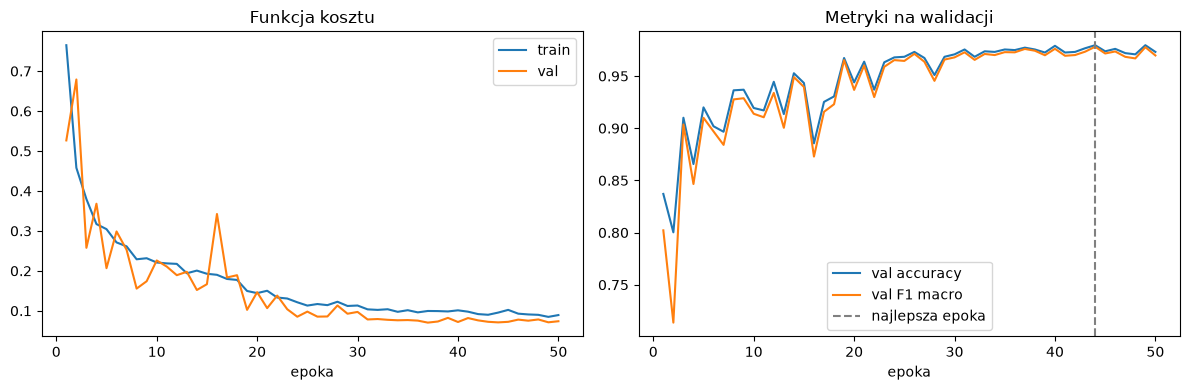

In [69]:
hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
axes[0].set_title("Funkcja kosztu"); axes[0].set_xlabel("epoka"); axes[0].legend()

axes[1].plot(hist["epoch"], hist["val_acc"], label="val accuracy")
axes[1].plot(hist["epoch"], hist["val_f1"], label="val F1 macro")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label="najlepsza epoka")
axes[1].set_title("Metryki na walidacji"); axes[1].set_xlabel("epoka"); axes[1].legend()
plt.tight_layout()
plt.show()

### Podsumowanie modelowania

Została stworzona własna sieć CNN z trzema blokami (dwie warstwy Conv 3x3 + BatchNorm + ReLU, potem MaxPool). Liczba filtró rośnie 32 -> 64 -> 128, a obraz maleje 28 -> 14 -> 7 -> 3. Na końcu Global Average Pooling, Dropout (0.3) i warstwa liniowa z 8 wyjściami. Sieć ma ok. 289 tyś parametrów.

W kwestii funkcji kosztu to entropia krzyżowa z wagami klas liczonymi z train (odwrotnie proporcjonalnie do liczebności), żeby rzadkie klasy maiły większy wpływ na uczenie.

Jako optymalizator wybrano AdamW (lr = 0.001, weight decay = 0.0001), który dobiera krok osobno dla każdej wagi i szybko zbiega, a weight decay ogranicza przeuczanie. ReduceLROnPlateau zmniejsza lr o połowę, gdy val F1 nie rośnie przez 3 epoki.

Wybrane metryki walidacyjne - po każdej epoce liczę F1 macro na val i zapisuję wagi z najlepszej epoki (checkpoint), przerywam trening po 8 epokach bez poprawy (early stopping) oraz sterują nim zmiany learning rate.

Wynik:
Najlepszy model był w epoce 44, val F1 macro = 0.978. Krzywe nie wskazują na przeuczenie: val loss maleje razem z train loss. Train loss jest wyższy od val loss, bo na treningu działają augmentacja i dropout. Early stopping się nie uruchomił (model poprawiał się do późnyxh epok).

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

In [70]:
from sklearn.metrics import balanced_accuracy_score

test_loss, test_acc, test_f1, test_preds = evaluate(model, test_loader, criterion)

print(f"Accuracy:          {test_acc:.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, test_preds):.4f}")
print(f"F1 macro:          {test_f1:.4f}\n")
print(classification_report(y_test, test_preds, target_names=CLASS_NAMES, digits=3))

Accuracy:          0.9684
Balanced accuracy: 0.9686
F1 macro:          0.9666

                         precision    recall  f1-score   support

                bazofil      0.944     0.963     0.953       244
              eozynofil      0.997     0.992     0.994       624
            erytroblast      0.984     0.965     0.974       311
niedojrzałe granulocyty      0.920     0.929     0.924       579
               limfocyt      0.972     0.984     0.978       243
                monocyt      0.916     0.954     0.934       284
              neutrofil      0.988     0.962     0.975       666
            płytka krwi      1.000     1.000     1.000       470

               accuracy                          0.968      3421
              macro avg      0.965     0.969     0.967      3421
           weighted avg      0.969     0.968     0.969      3421



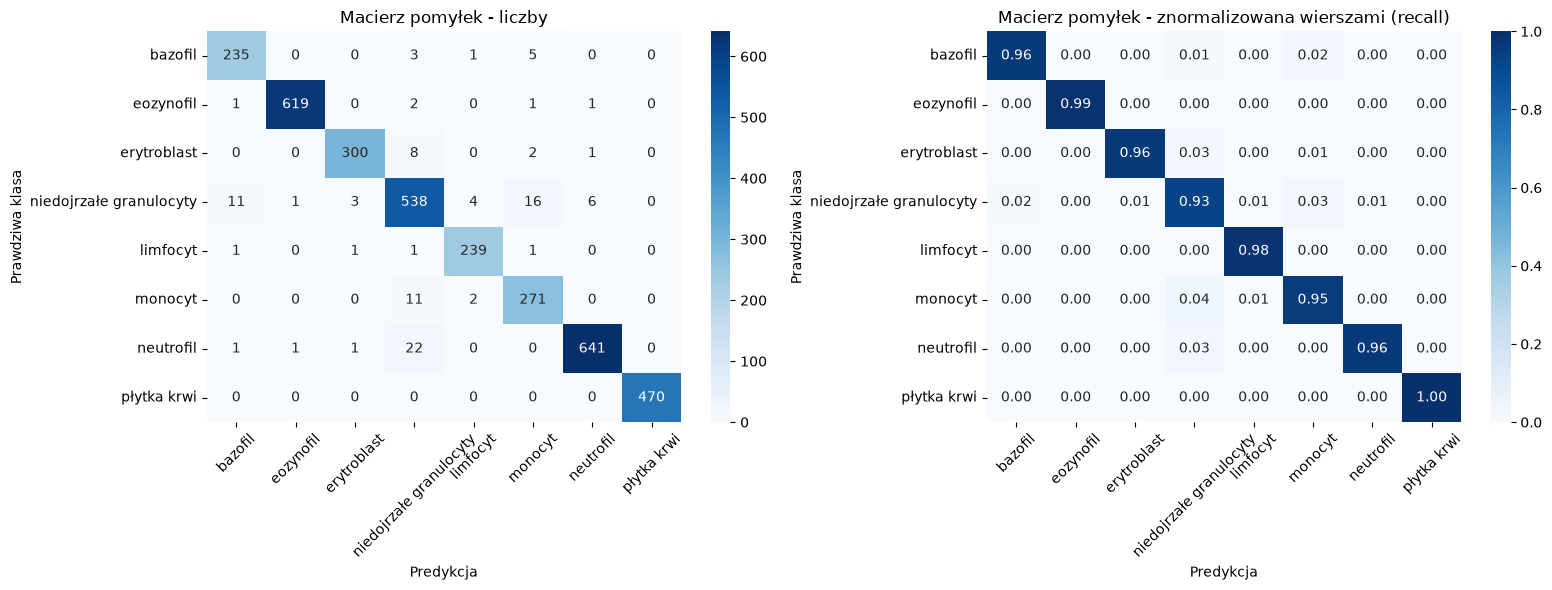

In [71]:
cm = confusion_matrix(y_test, test_preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_title("Macierz pomyłek - liczby")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[1].set_title("Macierz pomyłek - znormalizowana wierszami (recall)")
for ax in axes:
    ax.set_xlabel("Predykcja"); ax.set_ylabel("Prawdziwa klasa")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [72]:
import torch.nn.functional as F

class GradCAM:
    """Grad-CAM (Selvaraju i in., 2017) dla wybranej warstwy splotowej."""
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save)

    def _save(self, module, inp, out):
        self.activations = out
        if out.requires_grad:            # w evaluate() (no_grad) hook nic nie robi
            out.register_hook(lambda g: setattr(self, "gradients", g))

    def __call__(self, x, class_idx=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device)
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        self.model.zero_grad()
        logits[0, class_idx].backward()

        # 1) waga każdego kanału = średni gradient po mapie cech
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        # 2) ważona suma map cech + ReLU (interesuje tylko wpływ "za" klasą)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        # 3) powiększenie z 7x7 do 28x28 i normalizacja do 0–1
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        prob = F.softmax(logits, dim=1)[0, class_idx].item()
        return cam, class_idx, prob

# ostatnia warstwa ReLU w trzecim bloku (mapy 7x7, przed MaxPool)
gradcam = GradCAM(model, model.features[2][5])

In [73]:
rng = np.random.default_rng(42)

# 4 klasy z największą liczbą błędów 
errors_per_class = np.array([(test_preds[y_test == c] != c).sum() for c in range(NUM_CLASSES)])
classes_to_show = np.argsort(errors_per_class)[::-1][:4]
print("Wybrane klasy:", [CLASS_NAMES[c] for c in classes_to_show])

correct_idx, wrong_idx = [], []
for c in classes_to_show:
    ok  = np.where((y_test == c) & (test_preds == c))[0]
    bad = np.where((y_test == c) & (test_preds != c))[0]
    correct_idx += list(rng.choice(ok,  size=min(2, len(ok)),  replace=False))
    wrong_idx   += list(rng.choice(bad, size=min(2, len(bad)), replace=False))

Wybrane klasy: ['niedojrzałe granulocyty', 'neutrofil', 'monocyt', 'erytroblast']


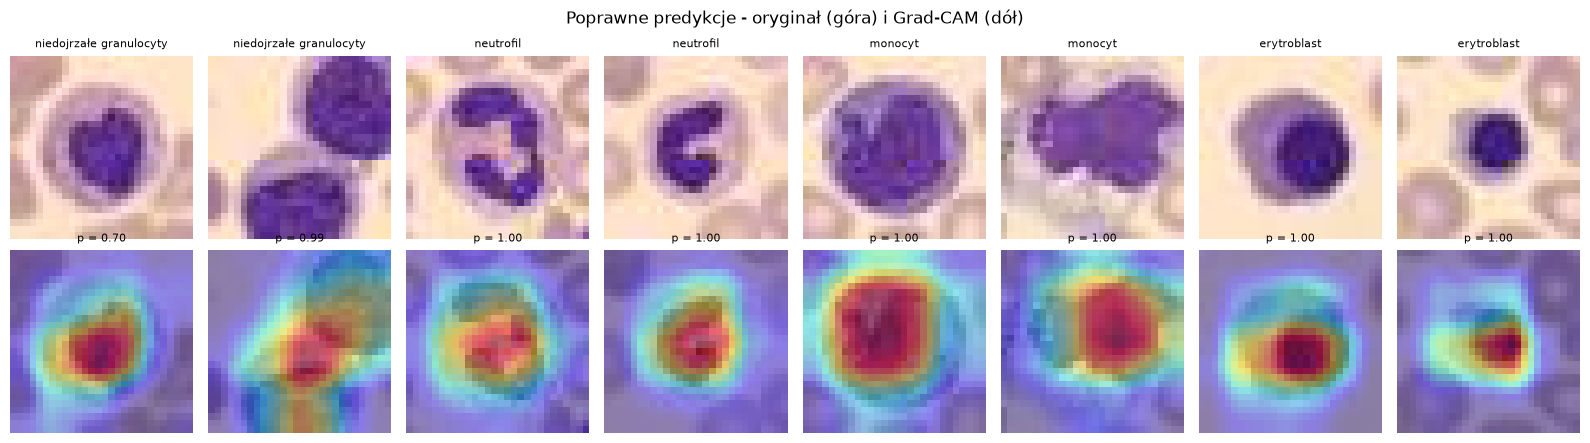

In [74]:
# Grad-CAM dla poprawnych predykcji
fig, axes = plt.subplots(2, len(correct_idx), figsize=(2 * len(correct_idx), 4.5))
for k, i in enumerate(correct_idx):
    cam, pred, prob = gradcam(test_ds[i][0])
    axes[0, k].imshow(X_test[i])
    axes[0, k].set_title(f"{CLASS_NAMES[y_test[i]]}", fontsize=8)
    axes[1, k].imshow(X_test[i])
    axes[1, k].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"p = {prob:.2f}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Poprawne predykcje - oryginał (góra) i Grad-CAM (dół)")
plt.tight_layout()
plt.show()

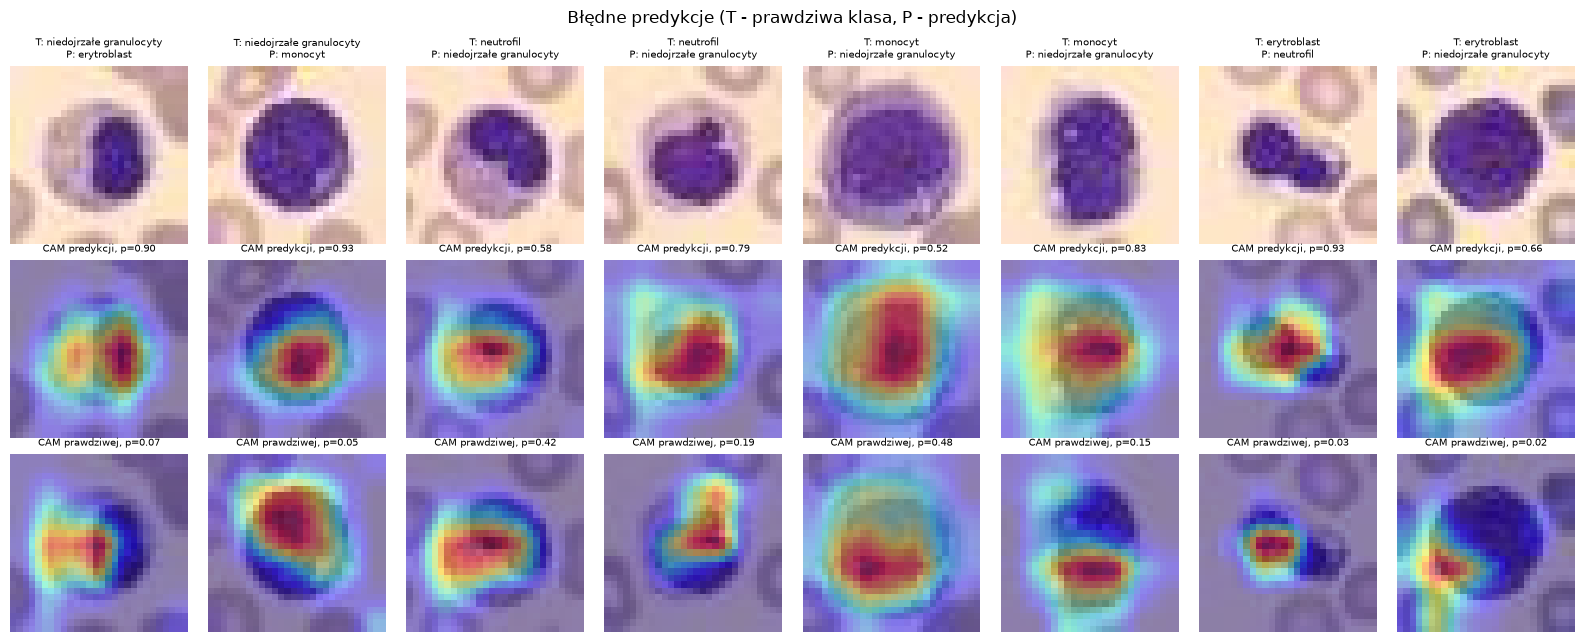

In [75]:
# Grad-CAM dla błędnych predykcji
fig, axes = plt.subplots(3, len(wrong_idx), figsize=(2 * len(wrong_idx), 6.5))
for k, i in enumerate(wrong_idx):
    x = test_ds[i][0]
    cam_pred, pred, prob_pred = gradcam(x)                          # dlaczego model wybrał źle
    cam_true, _, prob_true   = gradcam(x, class_idx=int(y_test[i])) # co widzi dla prawdziwej klasy

    axes[0, k].imshow(X_test[i])
    axes[0, k].set_title(f"T: {CLASS_NAMES[y_test[i]]}\nP: {CLASS_NAMES[pred]}", fontsize=7)
    axes[1, k].imshow(X_test[i]); axes[1, k].imshow(cam_pred, cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"CAM predykcji, p={prob_pred:.2f}", fontsize=7)
    axes[2, k].imshow(X_test[i]); axes[2, k].imshow(cam_true, cmap="jet", alpha=0.45)
    axes[2, k].set_title(f"CAM prawdziwej, p={prob_true:.2f}", fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Błędne predykcje (T - prawdziwa klasa, P - predykcja)")
plt.tight_layout()
plt.show()

### Podsumowanie oceny i wyjaśnialności

Wynik na teście jest zblizony do wyniku na walidacji (F1 równe 0.967 i 0.978) więc model dobrze generalizuje. Najsłabiej rozpoznawane klasy: ['niedojrzałe granulocyty', 'neutrofil', 'monocyt', 'erytroblast'].

Metoda Grad-CAM. Wagi kanałów ostatniej warstwy splotowej to uśrednione gradienty wyniku klasy (równanie 1), a mapa to ReLU z ważonej sumy map cech (równanie 2), powiększona do rozmiaru obrazu. Pokazuje, które obszary najbardziej wpłynęły na decyzję. Zaimplementowano ją na podstawie użytych źródeł i narzędzi.

Obserwacje:
- Poprawne predykcje - mapa obejmuje komórkę, a nie tło.
- Błędne predykcje: np. mapy dla klasy przewidzianej i prawdziwej wskazują ten sam obszar, więc model patrzył na komórkę, ale jej cechy były niejednoznaczne. Porównanie map dla obu klas jest wzorowane na rozdziale 6.1 artykułu.

Ograniczenia:
- Niska rozdzielczość (7×7 rozciągnięte do 28×28): pokazuje przybliżony obszar, nie szczegóły.
- Wynik zależy od wybranej warstwy, a ReLU ukrywa obszary przemawiające przeciw klasie.
- Mapa nie dowodzi poprawnego rozumowania. Adebayo i in. (2018) pokazali, że niektóre metody
  dają przekonujące mapy nawet dla losowego modelu. Grad-CAM przeszedł te testy, ale nadal
  pokazuje uwagę modelu, a nie medyczną poprawność.
- Analiza kilku przykładów jest jakościowa i nie uogólnia się statystycznie.


### Źródła i narzędzia
- R. R. Selvaraju i in., "Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization", ICCV 2017, rozdział 3. https://arxiv.org/abs/1610.02391
- Dokumentacja PyTorcha:
Module.register_forward_hook:
https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook
Tensor.register_hook:
https://pytorch.org/docs/stable/generated/torch.Tensor.register_hook.html
torch.nn.functional.interpolate:
https://pytorch.org/docs/stable/generated/torch.nn.functional.interpolate.html
- Claude.ai:
przy wyjaśnianiu działania poszczególnych elementów (warstwy sieci, funkcja kosztu, optymalizator, early stopping, równania Grad-CAM), pomoc w przełożeniu opisu metody Grad-CAM z publikacji na kod w PyTorchu, przy wyszukaniu literatury dotyczącej metod wyjaśnialności.



## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.